# Loan Default Prediction

This project predicts **loan approval** (`Loan_Status`: Y/N).

The labeled training file contains 614 applications. The separate test file contains 367 applications without labels. We will evaluate using a validation split from the labeled file; the unlabeled test file cannot produce an accuracy score.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Import libraries and read the data

In [ ]:
# pandas reads and organizes the CSV tables; NumPy provides numeric helpers.
import numpy as np
import pandas as pd
# Matplotlib and Seaborn create the charts used in the EDA section.
import matplotlib.pyplot as plt
import seaborn as sns
# Scikit-learn utilities split data and keep preprocessing inside model pipelines.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Metrics summarize different kinds of classification performance.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
# Three classifiers will be compared on the same validation data.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# The training CSV has known outcomes; the test CSV has applicant data only.
train_df = pd.read_csv('/content/drive/MyDrive/Loan_Default_Predicition/Dataset/train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/Loan_Default_Predicition/Dataset/test.csv')
# Check dimensions, sample values, and data types before analysis.
print('Training shape:', train_df.shape)
print('Test shape:', test_df.shape)
display(train_df.head())
train_df.info()

Training shape: (614, 13)
Test shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


## Inspect the data
`Loan_ID` is an identifier and is excluded from model features. `Loan_Status` is the label in the training file only.

In [ ]:
# Name the label column so the same target reference is reused below.
TARGET = 'Loan_Status'
# Confirm the files have the expected fields.
print('Training columns:', train_df.columns.tolist())
print('Test columns:', test_df.columns.tolist())
# See whether the two approval classes are balanced or uneven.
print('Target counts:\n', train_df[TARGET].value_counts(dropna=False))
print('Target proportions:\n', train_df[TARGET].value_counts(normalize=True).round(3))
# Missing values need imputation; duplicate rows can distort evaluation.
print('Missing values:\n', train_df.isna().sum().sort_values(ascending=False))
print('Duplicate rows:', train_df.duplicated().sum())
# Summary statistics help reveal ranges, skew, and category frequencies.
display(train_df.describe(include='all').T)

Training columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']
Test columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
Target counts:
 Loan_Status
Y    422
N    192
Name: count, dtype: int64
Target proportions:
 Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64
Missing values:
 Credit_History       50
Self_Employed        32
LoanAmount           22
Dependents           15
Loan_Amount_Term     14
Gender               13
Married               3
Education             0
Loan_ID               0
CoapplicantIncome     0
ApplicantIncome       0
Property_Area         0
Loan_Status           0
dtype: int64
Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP002990,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


## Exploratory data analysis
Look for patterns and write your observations in the markdown prompt below. Associations do not prove that a feature causes approval.

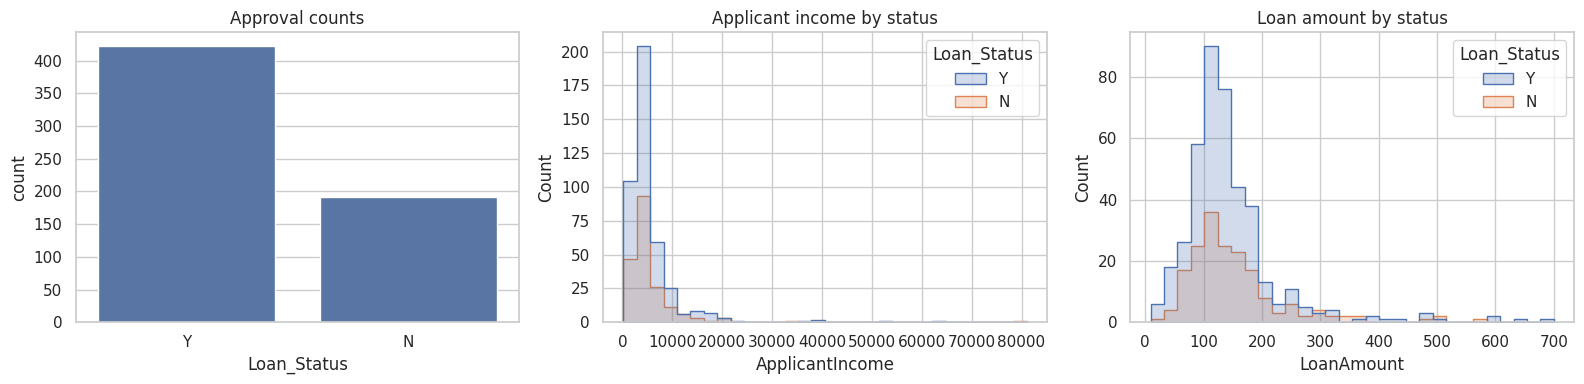

In [ ]:
# Use a consistent visual style for all charts.
sns.set_theme(style='whitegrid')
# Put target balance and two numeric distributions side by side.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=train_df, x=TARGET, ax=axes[0])  # Number of approved and rejected applications
sns.histplot(data=train_df, x='ApplicantIncome', hue=TARGET, bins=30, element='step', ax=axes[1])  # Income distributions by outcome
sns.histplot(data=train_df, x='LoanAmount', hue=TARGET, bins=30, element='step', ax=axes[2])  # Loan amount distributions by outcome
axes[0].set_title('Approval counts')
axes[1].set_title('Applicant income by status')
axes[2].set_title('Loan amount by status')
plt.tight_layout()  # Prevent labels from overlapping
plt.show()

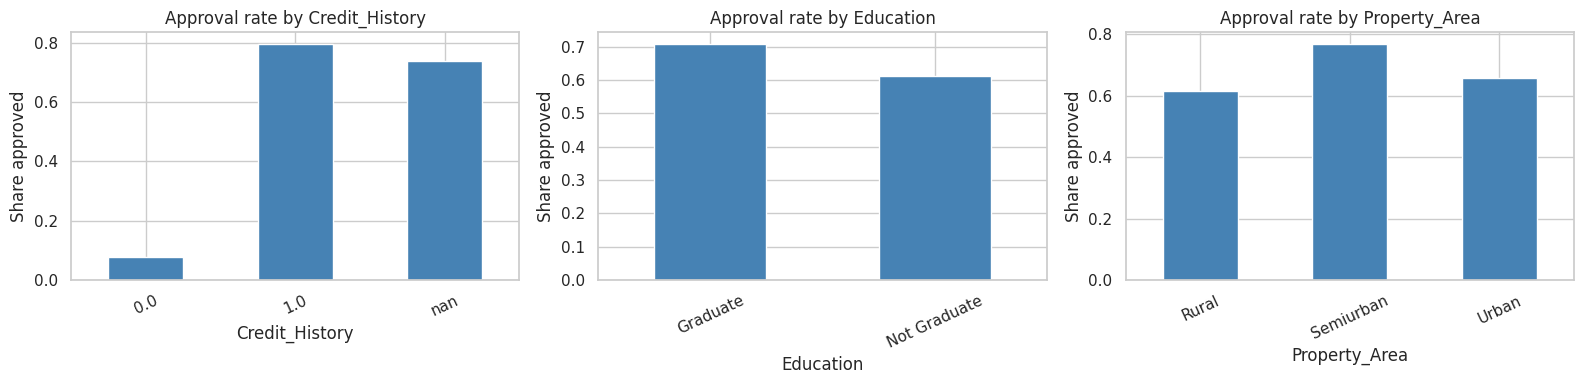

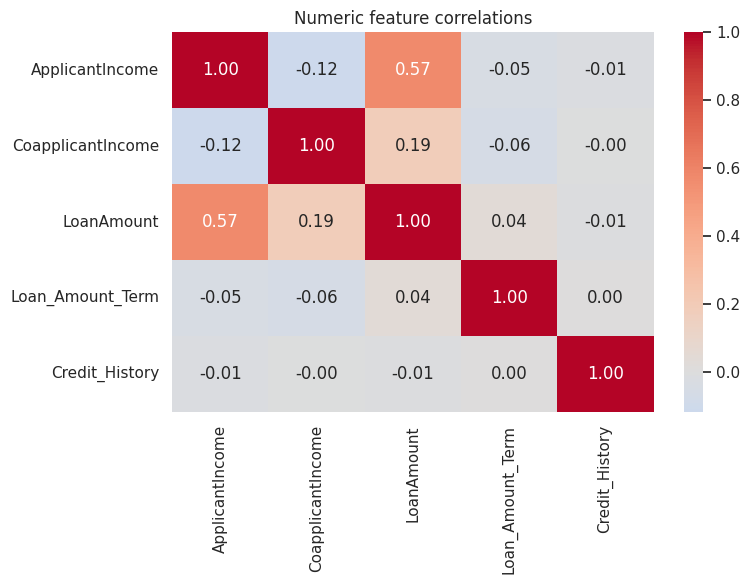

In [ ]:
# Compare approval rates for three categorical features.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Credit_History', 'Education', 'Property_Area']):
    # For each category, calculate the fraction of applications marked Y.
    approval_rate = train_df.groupby(col, dropna=False)[TARGET].apply(lambda values: (values == 'Y').mean())
    approval_rate.plot(kind='bar', ax=ax, title=f'Approval rate by {col}', color='steelblue')
    ax.set_ylabel('Share approved')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

# Correlations summarize linear relationships between numeric columns.
# Correlation does not imply that one feature causes another.
numeric_eda = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
plt.figure(figsize=(8, 6))
sns.heatmap(train_df[numeric_eda].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Numeric feature correlations')
plt.tight_layout()
plt.show()

## Split data and build preprocessing pipeline
We split before fitting the imputation and encoding steps. This prevents information from the validation rows leaking into preprocessing. One-hot encoding handles categories; scaling is included for Logistic Regression.

In [ ]:
# Separate predictors (X) from the outcome (y); drop the ID from predictors.
X = train_df.drop(columns=[TARGET, 'Loan_ID'], errors='ignore')
y = train_df[TARGET].map({'N': 0, 'Y': 1})  # Encode rejection as 0 and approval as 1
# Reserve 20% for validation and preserve the class ratio in both partitions.
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
# Identify number columns and text/category columns automatically.
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()
# Numeric missing values use the median, then scaling; categories use the
# most common value, then one-hot columns. Unknown categories are tolerated.
preprocessor = ColumnTransformer(transformers=[
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)
print('Train and validation sizes:', X_train.shape, X_valid.shape)

Numeric features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Train and validation sizes: (491, 11) (123, 11)


## Train and compare models
Compare accuracy, precision, recall, and F1. The positive class `1` is approval (`Y`). Consider which mistakes matter for your project when choosing a model.

In [ ]:
# Compare three standard classification algorithms.
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', min_samples_leaf=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', min_samples_leaf=2, random_state=42)
}
results = []  # Store the validation scores for the comparison table
fitted_models = {}  # Keep each fitted pipeline for later inspection
for name, estimator in models.items():
    # The pipeline applies the same preprocessing before each model.
    model_pipeline = Pipeline([('preprocessing', preprocessor), ('model', estimator)])
    model_pipeline.fit(X_train, y_train)  # Learn from training rows only
    valid_pred = model_pipeline.predict(X_valid)  # Predict the held-out rows
    fitted_models[name] = model_pipeline
    # Record multiple metrics because accuracy alone can be misleading.
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_valid, valid_pred),
        'Precision': precision_score(y_valid, valid_pred, zero_division=0),
        'Recall': recall_score(y_valid, valid_pred, zero_division=0),
        'F1': f1_score(y_valid, valid_pred, zero_division=0)
    })
# Sort by F1 as an initial selection rule; review all metrics before choosing.
results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.style.format({metric: '{:.3f}' for metric in ['Accuracy', 'Precision', 'Recall', 'F1']}))

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.829,0.872,0.882,0.877
1,Random Forest,0.821,0.839,0.918,0.876
2,Decision Tree,0.675,0.869,0.624,0.726


## Evaluate the selected model
The cell below selects the highest validation F1 score as a starting rule. Explain whether that is appropriate for your project and inspect the confusion matrix.

Selected model: Logistic Regression
                  precision    recall  f1-score   support

Not approved (N)       0.73      0.71      0.72        38
    Approved (Y)       0.87      0.88      0.88        85

        accuracy                           0.83       123
       macro avg       0.80      0.80      0.80       123
    weighted avg       0.83      0.83      0.83       123



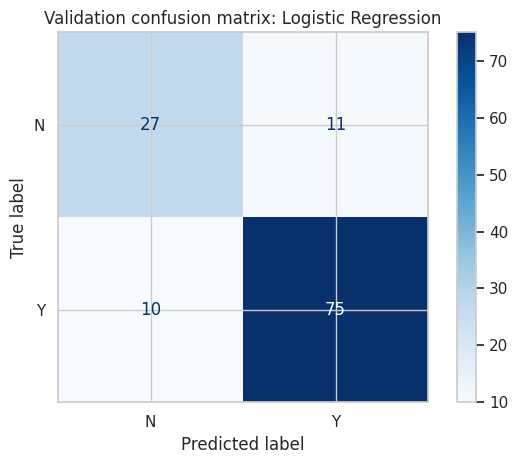

In [ ]:
# Select the top model according to validation F1 from the table above.
best_name = results_df.loc[0, 'Model']
best_model = fitted_models[best_name]
valid_pred = best_model.predict(X_valid)
print('Selected model:', best_name)
# The report shows precision, recall, F1, and support for each class.
print(classification_report(y_valid, valid_pred, target_names=['Not approved (N)', 'Approved (Y)'], zero_division=0))
# The confusion matrix counts correct and incorrect predictions by class.
ConfusionMatrixDisplay.from_predictions(y_valid, valid_pred, display_labels=['N', 'Y'], cmap='Blues')
plt.title(f'Validation confusion matrix: {best_name}')
plt.tight_layout()
plt.show()

## Predict the unlabeled test applications
This creates a CSV of predictions. It does not calculate accuracy because the test file does not contain true labels.

In [ ]:
# Remove the identifier before sending test rows through the trained pipeline.
test_X = test_df.drop(columns=['Loan_ID'], errors='ignore')
# Make predictions with the selected model; these are not test accuracy scores.
test_predictions = best_model.predict(test_X)
# Convert numeric predictions back to the original Y/N label format.
submission = pd.DataFrame({
    'Loan_ID': test_df['Loan_ID'] if 'Loan_ID' in test_df.columns else np.arange(len(test_df)),
    'Loan_Status': pd.Series(test_predictions).map({0: 'N', 1: 'Y'})
})
# Save the predictions
submission.to_csv('loan_approval_predictions.csv', index=False)
display(submission.head())
files.download('loan_approval_predictions.csv')